# T1 - Aprendizado Não Supervisionado - Dataset Regenera

Aprendizado de Máquina - Prof. Me. Otávio Parraga - PUCRS

Grupo: Dhara Hadi, Júlia Bettiol, Gabriel Ottonelli, Matheus Azevedo, Samuel Morales e Thomaz Szeckir

Neste trabalho buscamos estrutura escondida na coleção de microrganismos marinhos do Banco Regenera, sem nenhum rótulo guiando o aprendizado. 

-Na Tarefa A, de agrupamento, escolhemos o K-Means e o agrupamento hierárquico aglomerativo com ligação de Ward. 

-Na Tarefa B, de redução de dimensionalidade, escolhemos a PCA como estratégia linear e o UMAP como estratégia não linear.

Organização:

0. Configuração
1. Pré-processamento (Exploração, limpeza e transformações)
2. Tarefa A - Agrupamento
3. Tarefa B - Redução de dimensionalidade
4. Análise crítica (Sensibilidade ao pré-processamento e conclusão)

## 0. Configuração

A célula abaixo importa as bibliotecas que usamos ao longo do trabalho e fixa a semente aleatória em 42, para que todos os resultados possam ser reproduzidos.

In [1]:
import warnings  # utilidades e bibliotecas basicas
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency  # scipy: teste de independencia, hierarquico e comparacao de projecoes
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial import procrustes

from sklearn.preprocessing import StandardScaler, RobustScaler  # pre-processamento, agrupamento e reducao de dimensionalidade
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness

from sklearn.metrics import (  # metricas internas e externas de agrupamento
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_completeness_v_measure,
)

from sklearn.model_selection import StratifiedKFold, cross_val_score  # classificadores para medir a utilidade da reducao
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

import umap  # reducao nao linear

SEED = 42  # semente e caminho do arquivo
np.random.seed(SEED)
DATA_PATH = "Data_REG.tsv"

pd.set_option("display.max_columns", 50)  # opcoes de exibicao
sns.set_theme(style="whitegrid")

## 1. Pré-processamento

Aqui fazemos a exploração do arquivo, a limpeza e as transformações antes de rodar qualquer modelo.

### 1.1 Exploração

#### Leitura e inventário

Lemos tudo como texto (`dtype=str`). Se o pandas inferisse os tipos, ele transformaria em NaN o que não conseguisse converter, sem avisar, e a gente perderia a sujeira que precisa encontrar.

In [2]:
df_raw = pd.read_csv(DATA_PATH, sep="\t", dtype=str)  # tudo como texto para nao perder a sujeira
print(f"{df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas")
df_raw.head()

506 linhas e 33 colunas


,n°,GRAM,Cor,Cores,Borda,Textura,Forma,Brilho,Muco,Relevo,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23
0,1413,Negativo,1,2,0,1,1,2,0,1,0,0,Negativo,Negativo,1.2,0,0,-0.01,0.76,0.54,0.74,0.06,1,0,0,Positivo,1,1,3,1,3,0,2.767
1,1414,Positivo,1,2,0,1,4 & 1,2,0,0,0,2.33,Negativo,Negativo,1.2,-0.01,0.13,-0.04,0.28,0.1,0.09,0.04,0,2.8,3,Positivo,3,3,2,3,3,0,12.678
2,1415,Positivo,1,2,0,2 & 1,4 & 1,2,0,0,0,3.5,Negativo,Negativo,1.38,0,0.43,0.01,0.12,0.26,0.27,0.14,0,2,2.5,Positivo,3,3,3,3,3,3,6.87
3,1417,Negativo,1,2,0,1,1,2,0,1,0,0,Negativo,Negativo,1.25,0.67,0.11,0.03,0.99,0.67,0.24,0.11,2,0,0,Positivo,0,0,0,0,1,0,2.728
4,1418,Positivo,1,3,0,1,4 & 1,2,0,0,0,1.75,Negativo,Negativo,1.2,0,0.1,-0.02,0.24,0.26,0.09,0.17,0,2.33,1.2,Positivo,2,3,0,3,3,3,11.353


In [3]:
ID = "n°"  # identificador do isolado
MORPH = ["Cor", "Cores", "Borda", "Textura", "Forma", "Brilho", "Muco", "Relevo"]  # morfologia da colonia
ACTS = [c for c in df_raw.columns if c.startswith("Atividade")]  # as 23 atividades


def A(n):
    return f"Atividade {n:02d}"  # nome da coluna a partir do numero


BIN_ACTS = [A(n) for n in (1, 3, 4, 16)]  # binarias
ORD_ACTS = [A(n) for n in (13, 17, 18, 19, 20, 21, 22)]  # ordinais de 0 a 3
CONT_ACTS = [A(n) for n in (2, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 23)]  # continuas

assert sorted(BIN_ACTS + ORD_ACTS + CONT_ACTS) == sorted(ACTS)  # as tres listas cobrem todas as atividades sem repeticao
print(f"{len(ACTS)} atividades: {len(BIN_ACTS)} binárias, {len(ORD_ACTS)} ordinais e {len(CONT_ACTS)} contínuas")

23 atividades: 4 binárias, 7 ordinais e 12 contínuas


In [4]:
def tipo_coluna(c):
    if c == ID:
        return "identificador"
    if c == "GRAM":
        return "referência externa"
    if c in MORPH:
        return "morfologia (nominal)"
    if c in BIN_ACTS:
        return "atividade binária"
    if c in ORD_ACTS:
        return "atividade ordinal"
    return "atividade contínua"


inventario = pd.DataFrame(
    {
        "tipo": [tipo_coluna(c) for c in df_raw.columns],
        "n_distintos": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],  # sem contar o nan
        "n_ausentes": [df_raw[c].isna().sum() for c in df_raw.columns],
        "exemplos": [list(df_raw[c].dropna().unique()[:6]) for c in df_raw.columns],  # ate 6 valores distintos
    },
    index=df_raw.columns,
)
inventario

,tipo,n_distintos,n_ausentes,exemplos
n°,identificador,505,0,"[1413, 1414, 1415, 1417, 1418, 1419]"
GRAM,referência externa,7,0,"[Negativo, Positivo, Levedura, POSITIVO, Variá..."
Cor,morfologia (nominal),6,1,"[1, 2, 7, 3 & 5, 3, 6]"
Cores,morfologia (nominal),29,1,"[2, 3, 7, 5, 6, 5 & 3]"
Borda,morfologia (nominal),3,2,"[0, 2, 1]"
Textura,morfologia (nominal),4,2,"[1, 2 & 1, 2, 1 & 2]"
Forma,morfologia (nominal),7,3,"[1, 4 & 1, 4, 6, 4 & 2, 2]"
Brilho,morfologia (nominal),6,3,"[2, 1 & 2, 1, 4, 2 & 1, 0]"
Muco,morfologia (nominal),3,3,"[0, 1, 2]"
Relevo,morfologia (nominal),2,4,"[1, 0]"


São 506 linhas e 33 colunas, mas o identificador só tem 505 valores distintos, ou seja, tem um isolado repetido. Vamos tratar isso na limpeza.

Como os nomes dos ensaios são anonimizados, classificamos as atividades olhando os valores. Se a coluna só tem dois valores, é binária (01, 03, 04 e 16). Se só tem os inteiros de 0 a 3, consideramos ordinal (13 e 17 a 22), porque parece um nível de intensidade. O resto tem decimais e muitos níveis, então tratamos como contínua. No fim ficaram 4 binárias, 7 ordinais e 12 contínuas.

Os ausentes nas atividades estão concentrados na 20 (27), na 21 (17) e na 23 (3).

#### Valores das categóricas

Vamos ver como o GRAM e a morfologia foram escritos na planilha.

In [5]:
CAT_COLS = ["GRAM"] + MORPH  # gram so como referencia, morfologia para caracterizar grupos

for c in CAT_COLS:
    vc = df_raw[c].value_counts(dropna=False)
    print(f"--- {c} ({len(vc)} valores, contando o NaN)")
    print(", ".join(f"{v!r}: {n}" for v, n in vc.items()))  # repr mostra espacos sobrando nas strings
    print()

--- GRAM (7 valores, contando o NaN)
'Negativo': 244, 'Positivo': 218, 'Levedura': 40, 'POSITIVO': 1, 'Variável': 1, 'Levedura? não ': 1, 'Positiva': 1

--- Cor (7 valores, contando o NaN)
'1': 432, '2': 68, '3': 2, nan: 1, '7': 1, '3 & 5': 1, '6': 1

--- Cores (30 valores, contando o NaN)
'3': 199, '2': 141, '6': 34, '4': 30, '5': 19, '2 & 1': 16, '2 & 3': 9, '3 & 4': 9, '1': 7, '3 & 1': 7, '6 & 2': 4, '4 & 2': 4, '6 & 1': 3, '3 & 6': 3, '0': 3, '3 & 2': 2, '5 & 2': 2, '7': 2, '2 & 5': 1, '1 & 6': 1, '7 & 1': 1, '6 & 4': 1, '4 & 5': 1, '7 & 2': 1, '20': 1, '1 & 2': 1, 'OBS': 1, nan: 1, '5 & 3': 1, '6;2': 1

--- Borda (4 valores, contando o NaN)
'0': 395, '2': 63, '1': 46, nan: 2

--- Textura (5 valores, contando o NaN)
'1': 327, '2': 154, '1 & 2': 16, '2 & 1': 7, nan: 2

--- Forma (8 valores, contando o NaN)
'1': 355, '4': 93, '4 & 1': 37, '4 & 2': 8, '2': 6, nan: 3, '6': 2, '1 & 2': 2

--- Brilho (7 valores, contando o NaN)
'2': 372, '1': 92, '1 & 2': 28, '2 & 1': 8, nan: 3, '0': 2, 

Já dá para ver vários problemas. No GRAM, além de Negativo, Positivo e Levedura, aparecem "POSITIVO", "Positiva", "Variável" e "Levedura? não ", cada um em uma linha só.

Na morfologia tem muita célula com dois códigos, e às vezes a mesma combinação aparece nas duas ordens. Em Brilho, por exemplo, "1 & 2" aparece 28 vezes e "2 & 1" aparece 8. A coluna Cores é a pior: tem um "OBS", um "6;2" com outro separador e um "20", que foge muito dos outros códigos.

Também tem códigos que aparecem uma ou duas vezes, como o 7 em Cor e o 2 em Muco. Não temos como saber se é erro de digitação ou se é uma categoria rara mesmo, e vamos ter que decidir isso na limpeza.

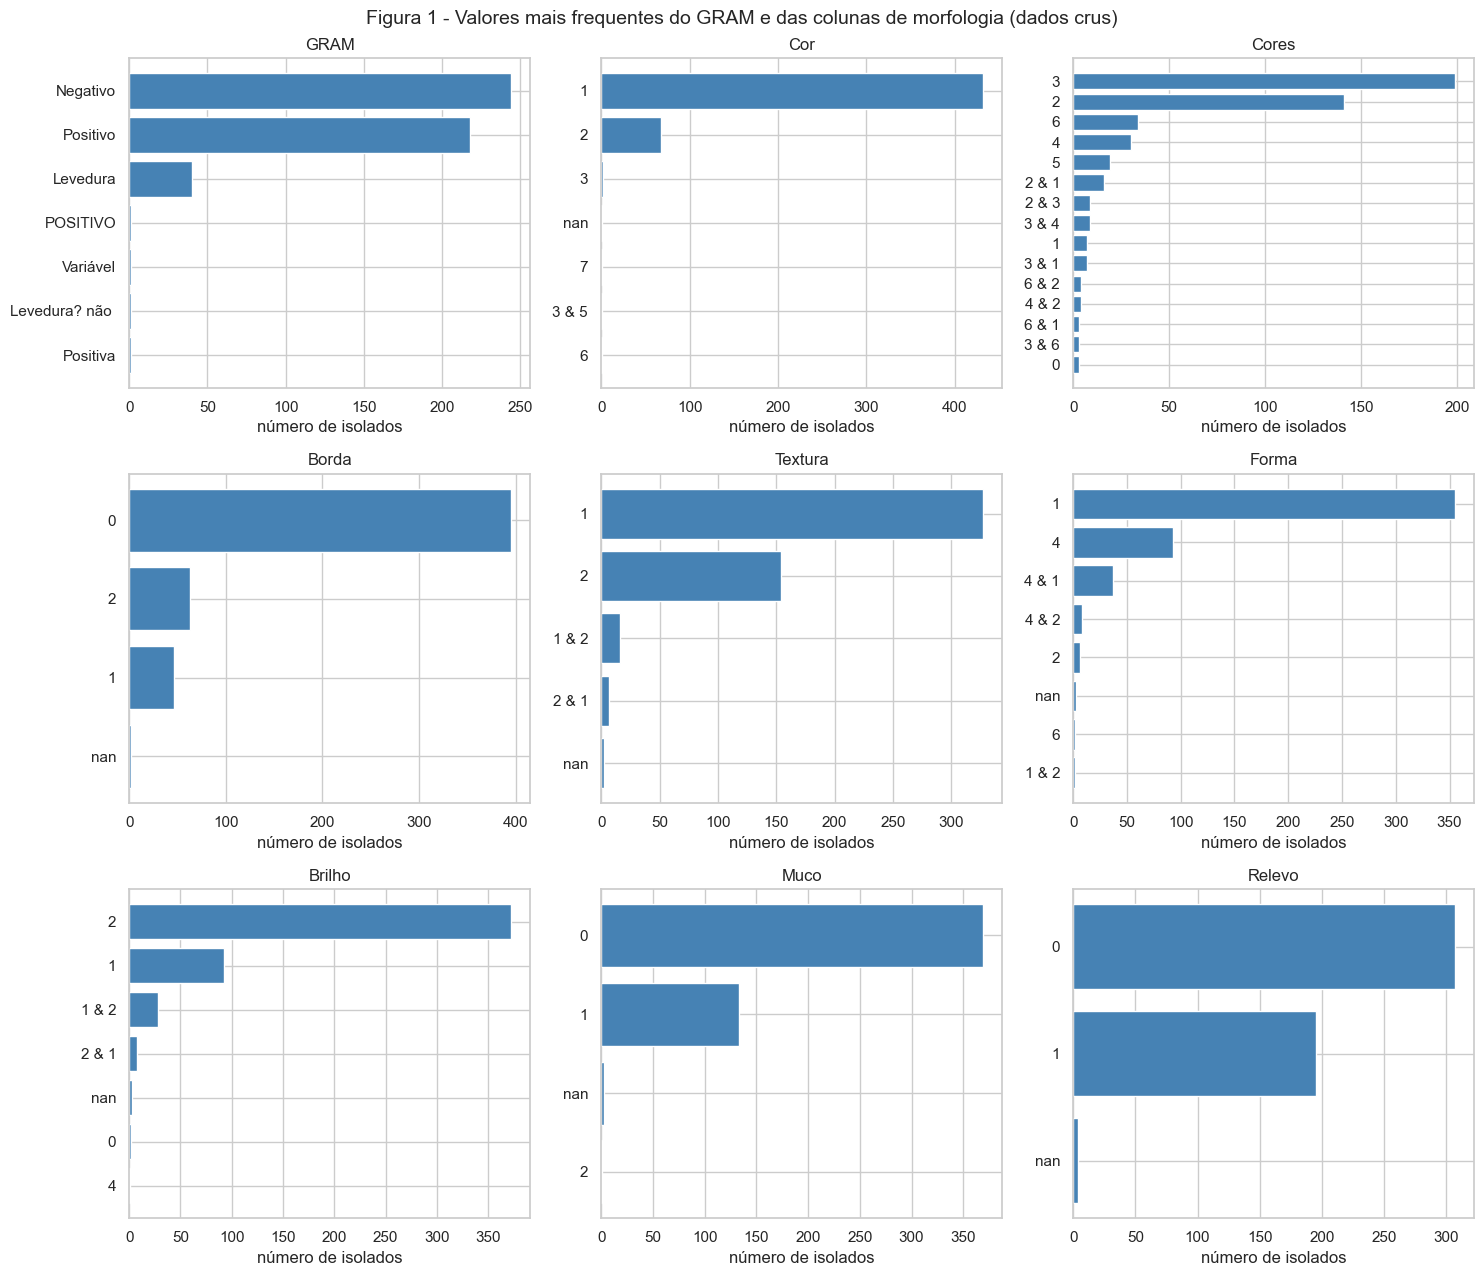

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for ax, c in zip(axes.ravel(), CAT_COLS):
    vc = df_raw[c].value_counts(dropna=False).head(15)  # os 15 valores mais frequentes
    rotulos = [str(v) for v in vc.index]  # str em cada valor para o nan virar rotulo
    ax.barh(rotulos[::-1], vc.values[::-1], color="steelblue")  # mais frequente no topo
    ax.set_title(c)
    ax.set_xlabel("número de isolados")
fig.suptitle("Figura 1 - Valores mais frequentes do GRAM e das colunas de morfologia (dados crus)", fontsize=14)
fig.tight_layout()
plt.show()

Na Figura 1 dá para ver que em quase todas as colunas um ou dois valores dominam. Em Cor, por exemplo, o código 1 tem 432 dos 506 isolados. As barrinhas do final são as combinações com "&" e as grafias estranhas. Por isso, quando formos caracterizar os grupos pela morfologia, a moda vai sair quase sempre igual, e vai ser mais útil ver quais categorias aparecem mais do que o normal em cada grupo.

#### Distribuições das atividades

Para conseguir fazer os gráficos, convertemos as atividades para número de forma provisória: Positivo vira 1, Negativo vira 0 e o resto passa pelo `pd.to_numeric`. Antes, conferimos o que não era número.

In [7]:
acts_txt = df_raw[ACTS].replace({"Positivo": "1", "Negativo": "0"})  # binarias escritas por extenso
acts_num = acts_txt.apply(pd.to_numeric, errors="coerce")  # conversao provisoria, so para explorar

perdidos = acts_txt.notna() & acts_num.isna()  # tinha texto e virou nan na conversao
for c in ACTS:
    if perdidos[c].any():
        print(f"{c}: {acts_txt.loc[perdidos[c], c].value_counts().to_dict()}")
print(f"Total de células que viraram NaN na conversão: {perdidos.values.sum()}")

Atividade 23: {'#NÚM!': 1}
Total de células que viraram NaN na conversão: 1


Só apareceu um "#NÚM!" na Atividade 23, que é erro de fórmula do Excel. Por enquanto ele virou NaN, mas vamos tratá-lo na limpeza.

In [8]:
desc_cont = acts_num[CONT_ACTS].describe().T
desc_cont["assimetria"] = acts_num[CONT_ACTS].skew()
desc_cont["pct_zeros"] = (acts_num[CONT_ACTS] == 0).mean() * 100  # proporcao de zeros em %
desc_cont["n_negativos"] = (acts_num[CONT_ACTS] < 0).sum()
desc_cont.round(3)

,count,mean,std,min,25%,50%,75%,max,assimetria,pct_zeros,n_negativos
Atividade 02,506.0,0.948,1.252,0.00,0.000,0.000,1.985,5.830,0.961,58.498,0
Atividade 05,506.0,0.707,0.682,0.00,0.000,1.000,1.250,3.600,0.428,44.466,0
Atividade 06,506.0,0.090,0.195,-0.06,0.000,0.010,0.020,0.810,2.139,34.387,34
Atividade 07,506.0,0.123,0.127,-0.08,0.040,0.100,0.160,0.810,2.237,3.953,34
Atividade 08,506.0,0.017,0.036,-0.19,0.000,0.010,0.040,0.160,-0.049,14.229,125
Atividade 09,506.0,0.724,0.315,0.00,0.470,0.750,0.980,1.510,-0.232,0.593,0
Atividade 10,506.0,0.444,0.200,0.00,0.302,0.420,0.580,1.080,0.290,0.791,0
Atividade 11,506.0,0.272,0.144,0.00,0.170,0.240,0.360,0.740,0.774,0.198,0
Atividade 12,506.0,0.192,0.116,-0.08,0.110,0.175,0.260,0.700,0.963,0.198,1
Atividade 14,506.0,0.955,1.693,0.00,0.000,0.000,1.485,15.500,2.882,63.439,0


As escalas são bem diferentes: a Atividade 23 vai até 577,893, enquanto várias outras não passam de 1. Sem padronizar, a 23 ia mandar sozinha nas distâncias.

Cinco colunas têm assimetria acima de 2 (06, 07, 14, 15 e 23), e algumas têm muito zero, como a 14, com 63,4% de zeros. Também aparecem negativos pequenos, principalmente na 08 (125 isolados), que parecem ruído de medida perto de zero. Isso importa porque o log não aceita valor negativo.

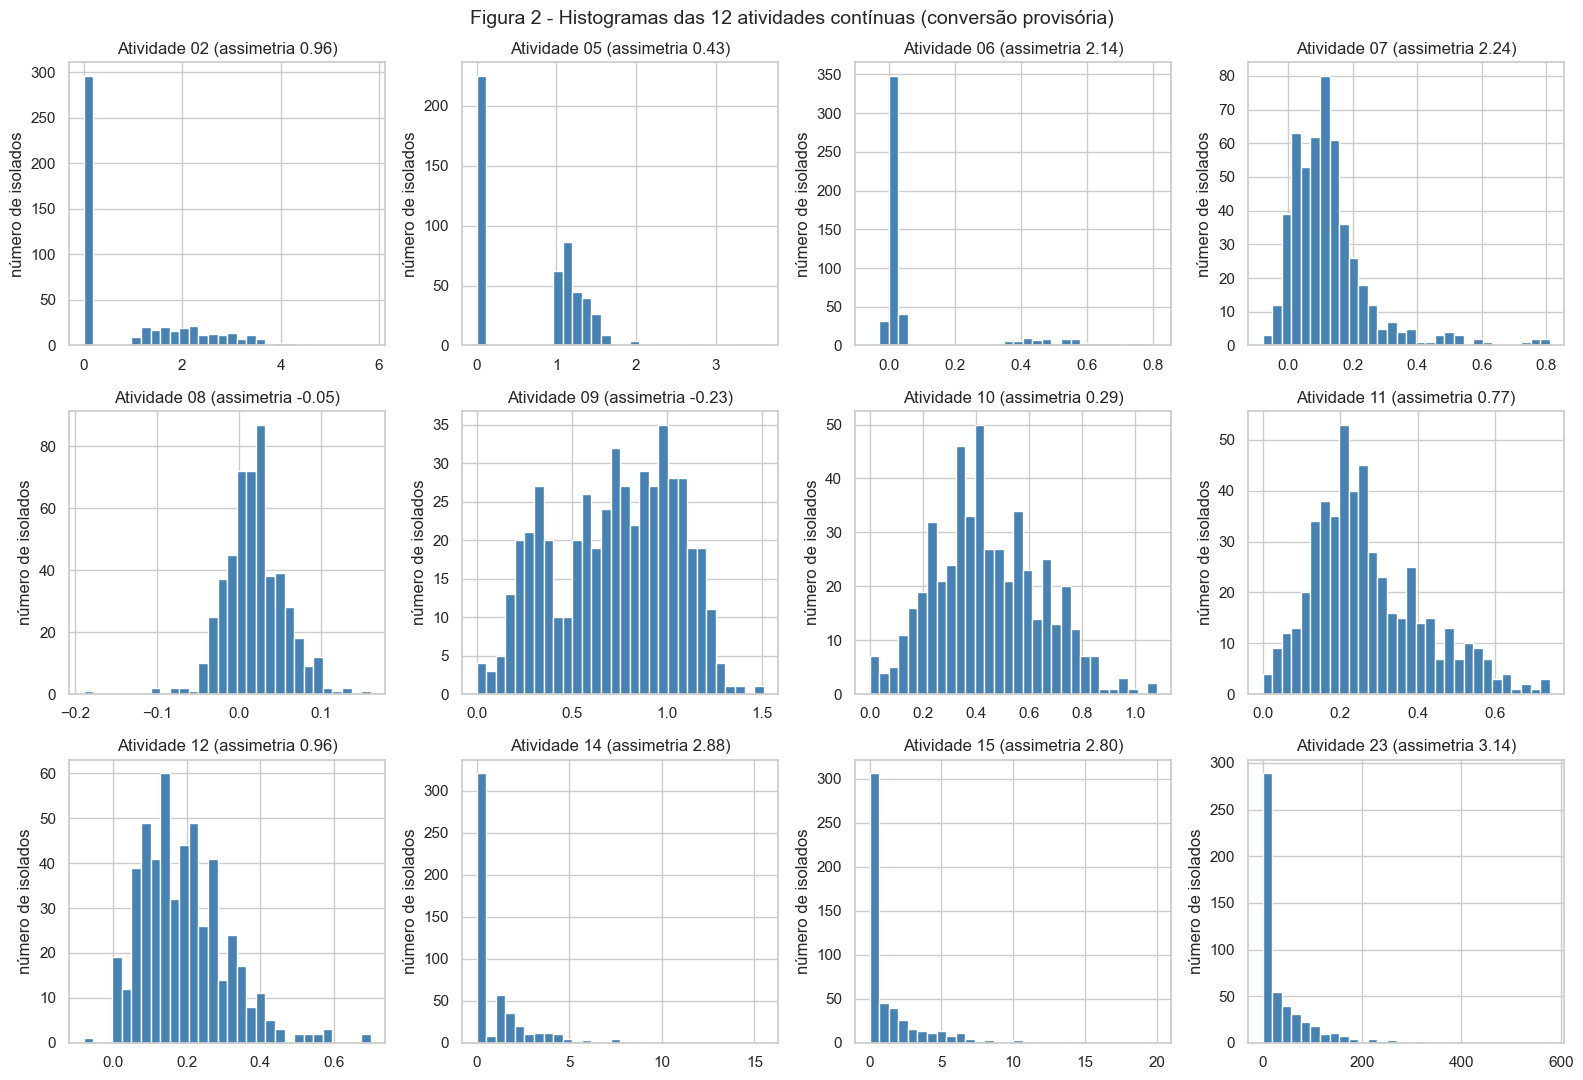

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, c in zip(axes.ravel(), CONT_ACTS):
    x = acts_num[c].dropna()
    ax.hist(x, bins=30, color="steelblue", edgecolor="white")
    ax.set_title(f"{c} (assimetria {x.skew():.2f})")
    ax.set_ylabel("número de isolados")
fig.suptitle("Figura 2 - Histogramas das 12 atividades contínuas (conversão provisória)", fontsize=14)
fig.tight_layout()
plt.show()

Na Figura 2, as Atividades 02, 14, 15 e 23 têm um pico grande perto do zero e uma cauda longa para a direita. A 05 e a 06 são curiosas: têm o pico no zero e depois um segundo grupo separado, como se o isolado ou não respondesse ou respondesse com uma intensidade típica. Já a 08, a 09 e a 10 são mais simétricas.

Pelo que vimos, as candidatas ao log são as cinco com assimetria acima de 2 (06, 07, 14, 15 e 23).

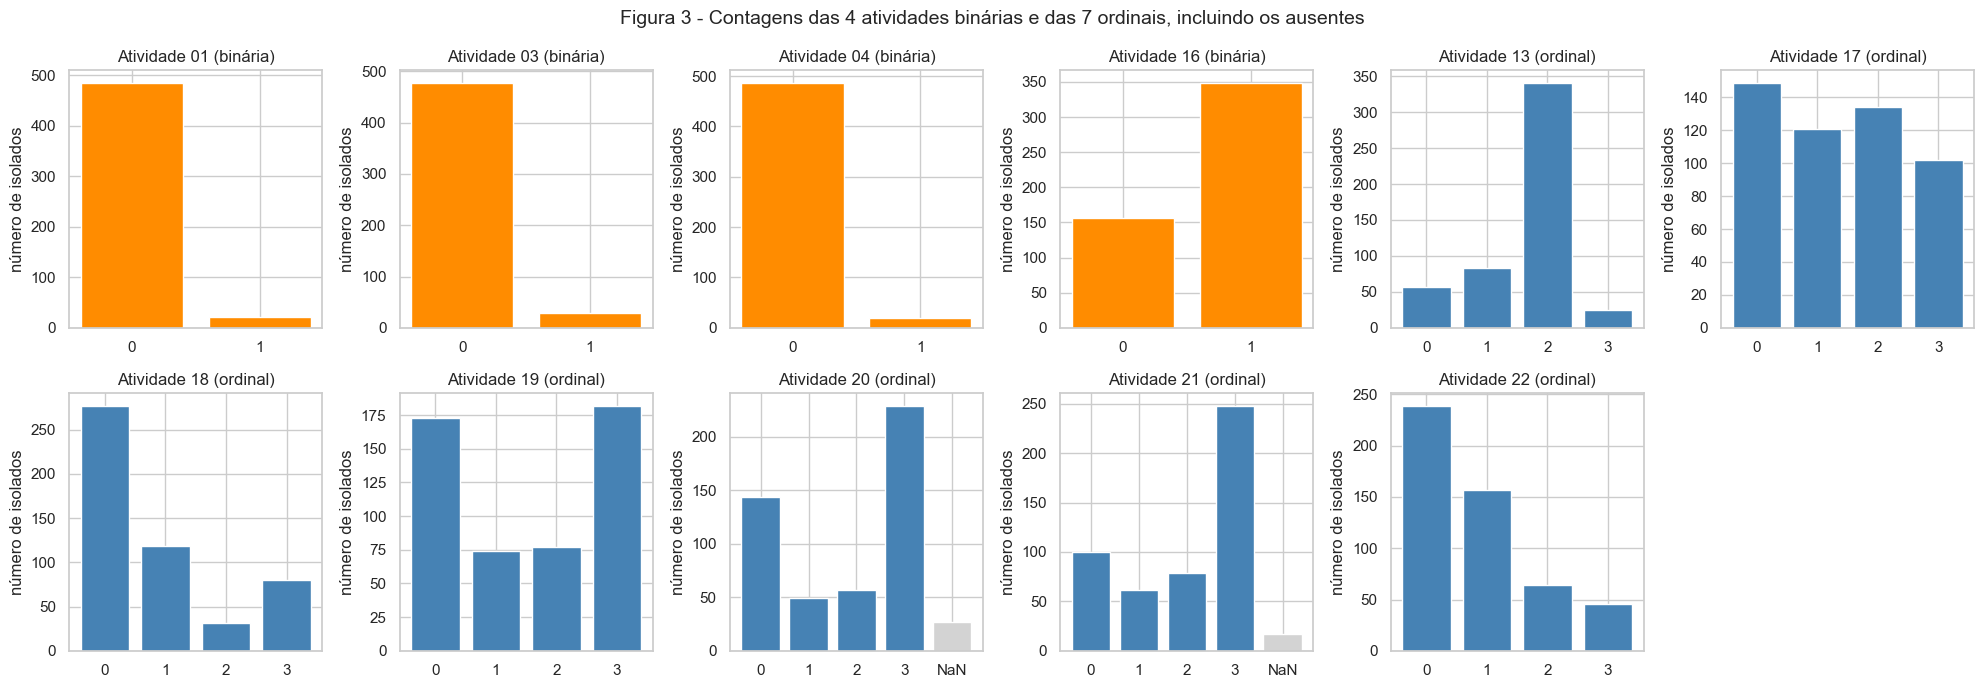

In [10]:
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for ax, c in zip(axes.ravel(), BIN_ACTS + ORD_ACTS):
    vc = acts_num[c].value_counts(dropna=False).sort_index(na_position="last")  # niveis em ordem e nan no fim
    rotulos = [str(int(v)) if pd.notna(v) else "NaN" for v in vc.index]
    cores = ["lightgray" if r == "NaN" else ("darkorange" if c in BIN_ACTS else "steelblue") for r in rotulos]
    ax.bar(rotulos, vc.values, color=cores)
    ax.set_title(f"{c} ({'binária' if c in BIN_ACTS else 'ordinal'})")
    ax.set_ylabel("número de isolados")
axes.ravel()[-1].axis("off")  # 11 colunas para 12 paineis
fig.suptitle("Figura 3 - Contagens das 4 atividades binárias e das 7 ordinais, incluindo os ausentes", fontsize=14)
fig.tight_layout()
plt.show()

Na Figura 3, três binárias quase nunca dão positivo: a 01 tem 21 positivos, a 03 tem 28 e a 04 tem 19. Isso preocupa porque, se padronizarmos, esses poucos positivos viram valores bem altos e pesam muito. A 16 é o contrário, com 349 positivos.

Nas ordinais cada atividade tem um formato: a 13 concentra quase tudo no nível 2, a 19 tem forma de U e a 17 é bem equilibrada. Os únicos ausentes estão na 20 e na 21.

#### Relações entre as atividades

Usamos Spearman em vez de Pearson porque temos binárias, ordinais e contínuas com cauda longa na mesma matriz. O Spearman usa a ordem dos valores, então não precisa de relação linear e não se deixa levar pelos valores extremos.

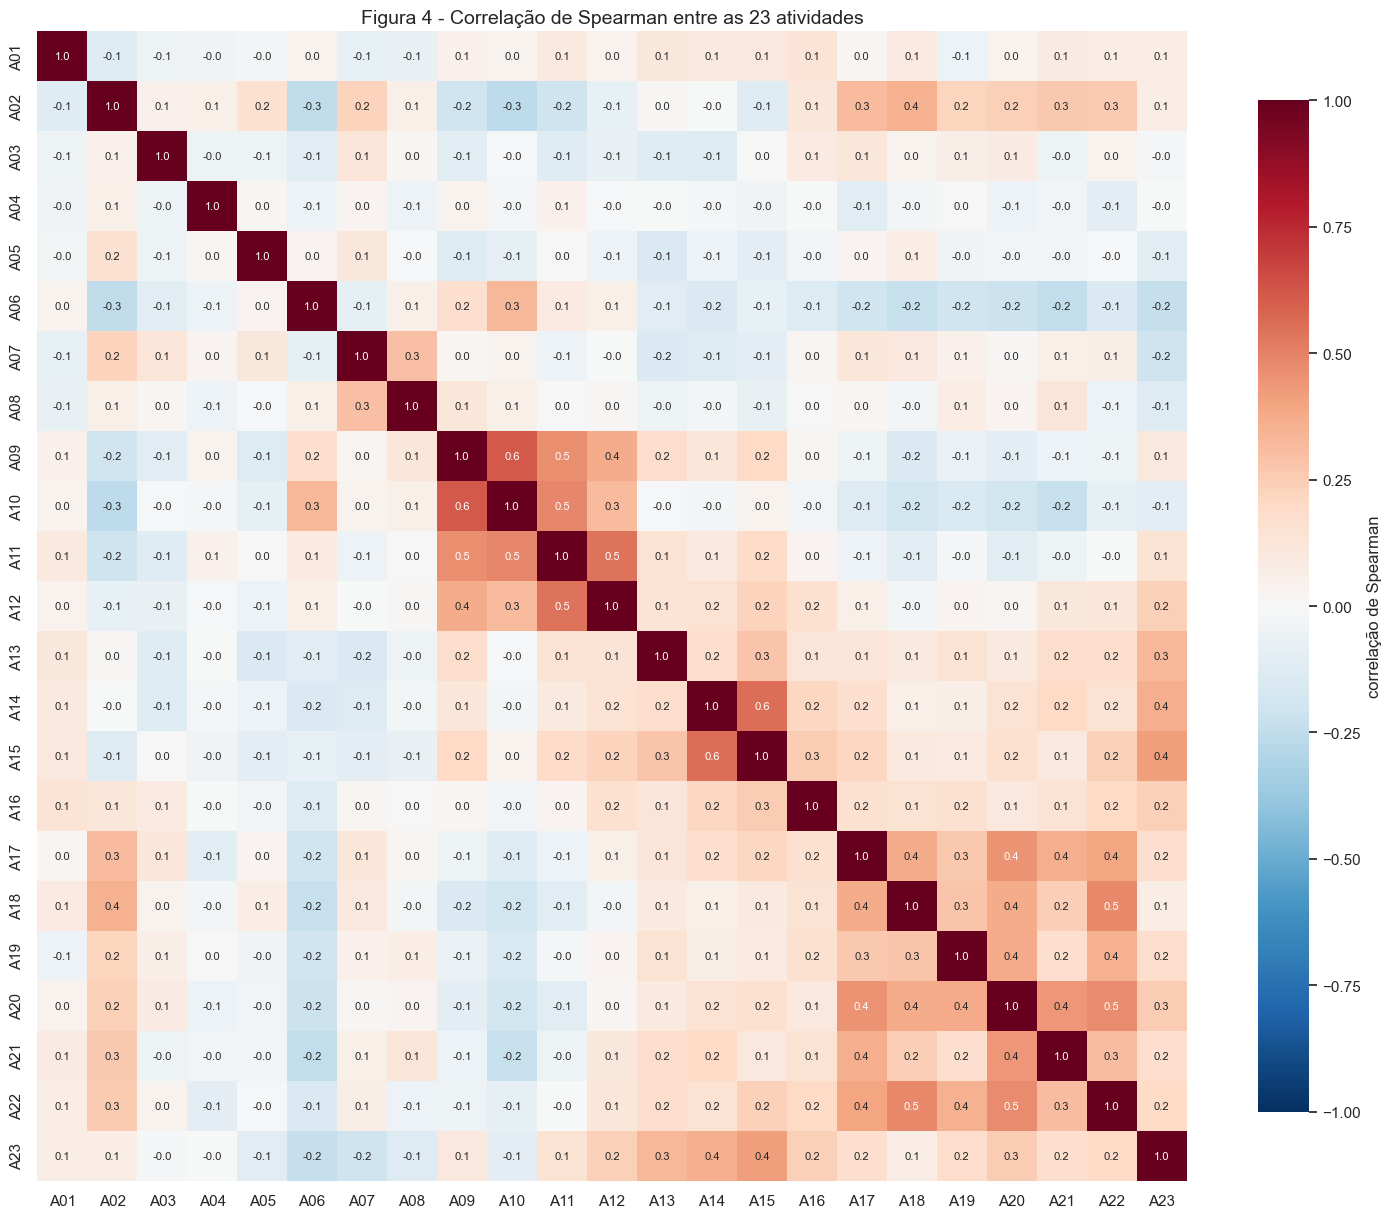

In [11]:
corr_sp = acts_num[ACTS].corr(method="spearman")  # par a par, ignorando os nan de cada par
curtos = [f"A{c.split()[-1]}" for c in ACTS]  # rotulos curtos a01, a02...

fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(
    corr_sp.set_axis(curtos, axis=0).set_axis(curtos, axis=1),
    annot=True, fmt=".1f", annot_kws={"size": 8},
    cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True,
    cbar_kws={"label": "correlação de Spearman", "shrink": 0.8},
    ax=ax,
)
ax.set_title("Figura 4 - Correlação de Spearman entre as 23 atividades", fontsize=14)
plt.tight_layout()
plt.show()

Na Figura 4 a maior parte da matriz fica perto de zero, e as correlações mais fortes aparecem em alguns blocos perto da diagonal. Nenhum par passa de 0,7, então nenhuma atividade é cópia de outra. As Atividades 01, 03, 04 e 05 praticamente não se relacionam com nenhuma outra.

In [12]:
triang = corr_sp.where(np.triu(np.ones(corr_sp.shape, dtype=bool), k=1))  # so acima da diagonal, sem repetir pares
pares = triang.stack().rename("spearman").reset_index()
pares.columns = ["atividade_1", "atividade_2", "spearman"]
pares["abs"] = pares["spearman"].abs()
top_pares = pares.sort_values("abs", ascending=False).head(12).drop(columns="abs").reset_index(drop=True)  # ordena pelo modulo
top_pares.round(3)

,atividade_1,atividade_2,spearman
0,Atividade 09,Atividade 10,0.610
1,Atividade 14,Atividade 15,0.562
2,Atividade 11,Atividade 12,0.541
3,Atividade 10,Atividade 11,0.487
4,Atividade 18,Atividade 22,0.482
5,Atividade 20,Atividade 22,0.476
6,Atividade 09,Atividade 11,0.464
7,Atividade 17,Atividade 20,0.446
8,Atividade 20,Atividade 21,0.439
9,Atividade 15,Atividade 23,0.417


Os pares mais correlacionados formam três blocos. O primeiro tem as Atividades 09, 10, 11 e 12, com o par mais forte de todos (09 e 10, com 0,610). O segundo é o das ordinais de 17 a 22, que aparecem em seis dos doze pares. O terceiro junta 14, 15 e 23, com 14 e 15 em 0,562.

Isso indica que as 23 atividades têm bem menos de 23 "direções" independentes, o que deve ajudar a PCA. Mas, como os ensaios são anonimizados, não dá para saber o que cada bloco mede.